# カテゴリの変数と生存の関係
性別・客室の等級・乗船した港などのカテゴリの変数ごとに生存率を比べ、生存と強く関係する変数を見つけます。2つの変数を組み合わせたクロス集計で、見かけの関係(交絡)にも注意します。

## 学習目標
- `groupby` でグループごとの生存率と人数を求められる
- `pivot_table`・`crosstab` で2つの変数を組み合わせて集計できる
- 棒グラフで生存率を比べられる
- 見かけの関係(交絡)に気づき、別の変数で説明できるか確かめられる

## グループごとの生存率

`Survived` は 0 / 1 なので、グループごとの **平均がそのまま生存率** になります。人数もあわせて確認するため、`agg` で平均(`mean`)と件数(`count`)を同時に求めます。

In [1]:
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 性別ごとのグループに分け、Survived の平均(=生存率)と件数(=人数)を同時に求める
train.groupby("Sex")["Survived"].agg(["mean", "count"]).round(3)

         mean  count
Sex                 
female  0.734    305
male    0.186    586


女性の生存率は 73%、男性は 19% で、大きな差があります。救命ボートへの乗船で「女性と子どもを優先」したことが表れています。

In [2]:
# 等級ごとの生存率と人数
train.groupby("Pclass")["Survived"].agg(["mean", "count"]).round(3)

         mean  count
Pclass              
1       0.590    217
2       0.434    196
3       0.251    478


等級が上がるほど生存率が高く、1 等は 59%、3 等は 25% です。

棒グラフで比べると、差がひと目でわかります。全体の生存率(約 37%)を補助線で入れておくと、各グループが平均より高いか低いかが読み取りやすくなります。

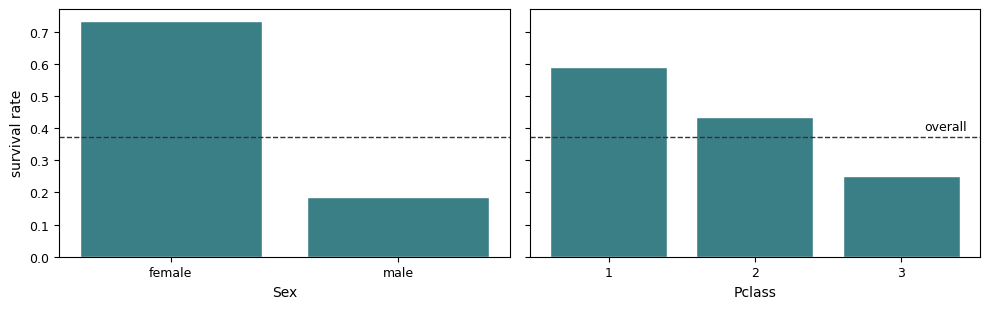

In [3]:
import matplotlib.pyplot as plt

# グラフに使う値を先に求めておく
rate_sex = train.groupby("Sex")["Survived"].mean()       # 性別ごとの生存率
rate_class = train.groupby("Pclass")["Survived"].mean()  # 等級ごとの生存率
overall = train["Survived"].mean()                       # 全体の生存率

# 1 行 2 列のグラフの枠を作る。sharey=True で 2 つのグラフの縦軸の目盛りをそろえる
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)

# 左:性別ごとの生存率の棒グラフ(横軸の位置 = グループ名、棒の高さ = 生存率)
axes[0].bar(rate_sex.index, rate_sex.values)
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("survival rate")

# 右:等級ごとの生存率の棒グラフ(等級は数値なので、astype(str) で文字にして横軸のラベルにする)
axes[1].bar(rate_class.index.astype(str), rate_class.values)
axes[1].set_xlabel("Pclass")

# 両方のグラフに、全体の生存率の補助線(水平の破線)を引く
for ax in axes:
    ax.axhline(overall, color="#333333", linestyle="--", linewidth=1)
# 右のグラフの補助線の上に、"overall" という注釈を書く
axes[1].text(2.45, overall + 0.02, "overall", ha="right", fontsize=9)

fig.tight_layout()
plt.show()

## 2つの変数を組み合わせる

性別と等級を組み合わせて生存率を求めます。`pivot_table` では、行(`index`)・列(`columns`)に使う変数と、集計する値(`values`)・集計の方法(`aggfunc`)を指定します。

In [4]:
# 行 = 性別、列 = 等級 として、Survived の平均(=生存率)を表にまとめる
train.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean").round(3)

Pclass      1      2      3
Sex                        
female  0.957  0.917  0.493
male    0.315  0.153  0.151


- 1 等・2 等の女性は 90% 以上が生存している
- 3 等の女性は 49% で、同じ女性でも等級によって大きく異なる
- 男性はどの等級でも低いが、1 等(32%)は 2 等・3 等(15%)の約 2 倍

性別と等級は、**どちらも** 生存と関係していることがわかります。

人数の割合を見るときは `crosstab` が便利です。`normalize="index"` を指定すると、行ごとの割合(行の合計が 1)になります。

In [5]:
# 行 = 性別、列 = 等級 の人数の表(クロス集計表)を作る
# normalize="index" で、人数を行ごとの割合(行の合計が 1)に変える
pd.crosstab(train["Sex"], train["Pclass"], normalize="index").round(3)

Pclass      1      2      3
Sex                        
female  0.305  0.236  0.459
male    0.212  0.212  0.577


男性の 58%、女性の 46% が 3 等の乗客です。男性の方が 3 等の割合が高いことも、男性の生存率の低さの一因になっています。

## 演習

学習用のデータで、乗船した港 `Embarked` ごとの生存率(`mean`)と人数(`count`)を求め、小数第3位まで表示してください。

In [ ]:
# @starter
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 港ごとのグループに分け、生存率と人数を同時に求める
# (1つ目の ____ にグループ分けに使う列名、2つ目・3つ目の ____ に集計の方法を文字列で入れる)
result = train.groupby("____")["Survived"].agg([____, ____])

# 小数第3位まで表示する
print(result.round(3))

In [6]:
# @solution
# @title: 乗船した港ごとの生存率
# @hint: agg には集計の方法を文字列のリストで渡します(例: ["mean", "count"])。
# @explanation: Cherbourg(C)から乗船した乗客の生存率は約 57% で、Queenstown(Q)の約 31%、Southampton(S)の約 32% より高くなっています。
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 港ごとのグループに分け、生存率(mean)と人数(count)を同時に求める
result = train.groupby("Embarked")["Survived"].agg(["mean", "count"])

# 小数第3位まで表示する
print(result.round(3))

           mean  count
Embarked              
C         0.569    188
Q         0.310     87
S         0.321    614


港によって生存率が違う理由を調べるため、乗船した港 `Embarked`(行)ごとに、客室の等級 `Pclass`(列)の **人数の割合**(行の合計が 1)を求め、小数第3位まで表示してください。

In [ ]:
# @starter
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 行 = 港、列 = 等級 のクロス集計表を作る
# (____ に、人数を行ごとの割合にするための引数を入れる)
table = pd.crosstab(train["Embarked"], train["Pclass"], ____)

# 小数第3位まで表示する
print(table.round(3))

In [7]:
# @solution
# @title: 港ごとの等級の内訳
# @hint: crosstab に normalize="index" を指定すると、行ごとの割合になります。
# @explanation: Cherbourg(C)から乗船した乗客は約 51% が 1 等で、ほかの港(Q は約 2%、S は約 19%)より 1 等の割合がずっと高くなっています。Queenstown(Q)は約 91% が 3 等です。
import pandas as pd

# 学習用のデータを読み込む
train = pd.read_csv("train.csv")

# 行 = 港、列 = 等級 のクロス集計表を、行ごとの割合(normalize="index")で作る
table = pd.crosstab(train["Embarked"], train["Pclass"], normalize="index")

# 小数第3位まで表示する
print(table.round(3))

Pclass        1      2      3
Embarked                     
C         0.505  0.101  0.394
Q         0.023  0.069  0.908
S         0.192  0.279  0.529


<!-- @question
type: choice
answer: Cherbourg から乗船した乗客には 1 等の乗客が多く、等級の違いが生存率の差に表れている可能性がある。
title: 港と生存率の関係の解釈
hint: 前の2問の結果を組み合わせて考えます。港ごとに、生存率の高い 1 等の乗客の割合はどうでしたか。
explanation: Cherbourg から乗船した乗客は約半数が 1 等で、1 等の乗客は生存率が高いため、港ごとの生存率の差の多くは等級の違いで説明できる可能性があります。このように、別の変数(等級)を通じて生じる見かけの関係を交絡といいます。港そのものが生存に影響したと結論づける前に、等級などの別の変数をそろえて比べる必要があります。
-->
前の2問の結果から、乗船した港と生存率の関係について言えることとして最も適切なものを選べ。

- Cherbourg の港で乗船すると、救命ボートに乗りやすかったと結論できる。
- Cherbourg から乗船した乗客には 1 等の乗客が多く、等級の違いが生存率の差に表れている可能性がある。
- 港ごとの人数が違うので、生存率を比べることには意味がない。
- 港と等級は関係がないので、港は等級とは別に生存に影響している。

## まとめ

- 0 / 1 の変数の平均は割合になる。`groupby(...).agg(["mean", "count"])` で生存率と人数を同時に確認する。
- 性別(女性 73%・男性 19%)と等級(1 等 59%・3 等 25%)は、生存と強く関係している。
- `pivot_table`・`crosstab` で2つの変数を組み合わせる。港と生存率のように、別の変数(等級)による見かけの関係(交絡)に注意する。